In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Load MNIST images
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten 28x28 images into 784 values
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Input
inputs = Input(shape=(784,))

# Encoder
encoded = Dense(128, activation="relu")(inputs)
encoded = Dense(32, activation="relu")(encoded)

# Decoder
decoded = Dense(128, activation="relu")(encoded)
outputs = Dense(784, activation="sigmoid")(decoded)

# Build autoencoder
autoencoder = Model(inputs, outputs)

# Compile
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Train: input is also the target
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    validation_data=(x_test, x_test)
)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0591 - val_loss: 0.0324
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0264 - val_loss: 0.0215
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0196 - val_loss: 0.0172
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0165 - val_loss: 0.0151
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0148 - val_loss: 0.0138
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0137 - val_loss: 0.0133
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0129 - val_loss: 0.0123
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0124 - val_loss: 0.0120
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0120 - val_loss: 0.0115
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0116 - val_loss: 0.0112


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


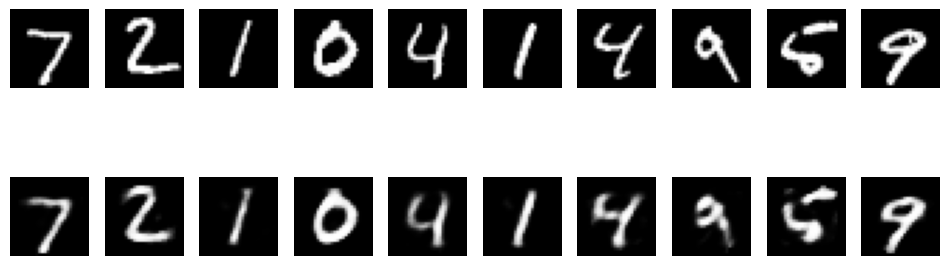

In [2]:
import matplotlib.pyplot as plt

reconstructed = autoencoder.predict(x_test[:10])

plt.figure(figsize=(12, 4))

for i in range(10):
    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()